In [4]:
import os

path = "/content/archive.zip"

print("Exists:", os.path.exists(path))

if os.path.exists(path):
    print("Size (MB):", round(os.path.getsize(path) / (1024 * 1024), 2))
    with open(path, "rb") as f:
        print("File signature:", f.read(4))

Exists: True
Size (MB): 346.33
File signature: b'PK\x03\x04'


In [6]:
import zipfile

with zipfile.ZipFile("/content/archive.zip", "r") as z:
    z.extractall("/content/intel_dataset")

print("Extraction complete")

Extraction complete


In [7]:
import os

root = "/content/intel_dataset"

for path, dirs, files in os.walk(root):
    level = path.replace(root, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(path) + "/")
        if level == 2:
            dirs.clear()

intel_dataset/
  seg_train/
    seg_train/
  seg_pred/
    seg_pred/
  seg_test/
    seg_test/


In [8]:
import os

train_dir = "/content/intel_dataset/seg_train/seg_train"

for folder in sorted(os.listdir(train_dir)):
    path = os.path.join(train_dir, folder)
    if os.path.isdir(path):
        print(folder, ":", len(os.listdir(path)), "images")

buildings : 2191 images
forest : 2271 images
glacier : 2404 images
mountain : 2512 images
sea : 2274 images
street : 2382 images


In [9]:
#load dataset
import tensorflow as tf

train_dir = "/content/intel_dataset/seg_train/seg_train"

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(150, 150),
    batch_size=32
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(150, 150),
    batch_size=32
)

print("Classes:", train_ds.class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Training batches: 351
Validation batches: 88


In [10]:
#build model
import tensorflow as tf
from tensorflow.keras import layers, models

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

model = models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(6, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
#train baseline CNN
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 27s 52ms/step - accuracy: 0.4450 - loss: 1.2806 - val_accuracy: 0.5456 - val_loss: 1.0156
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.5855 - loss: 0.9882 - val_accuracy: 0.6511 - val_loss: 0.8799
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.6465 - loss: 0.8679 - val_accuracy: 0.6864 - val_loss: 0.8185
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.6804 - loss: 0.8063 - val_accuracy: 0.7074 - val_loss: 0.7246
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.7118 - loss: 0.7409 - val_accuracy: 0.6935 - val_loss: 0.7498
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7257 - loss: 0.7072 - val_accuracy: 0.7787 - val_loss: 0.5958
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7438 - loss: 0.6729 - val_accuracy: 0.7548 - val_loss: 0.6230
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7555 - loss: 0.6408 - 

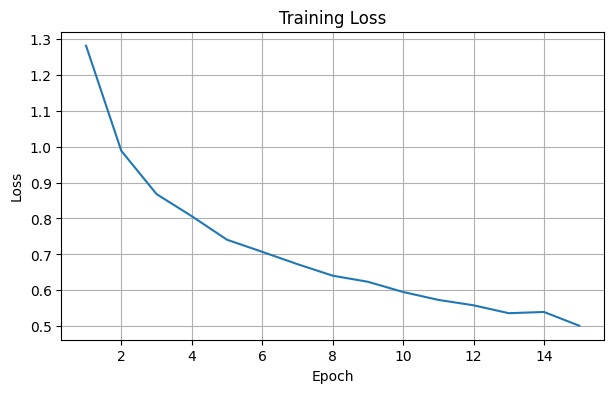

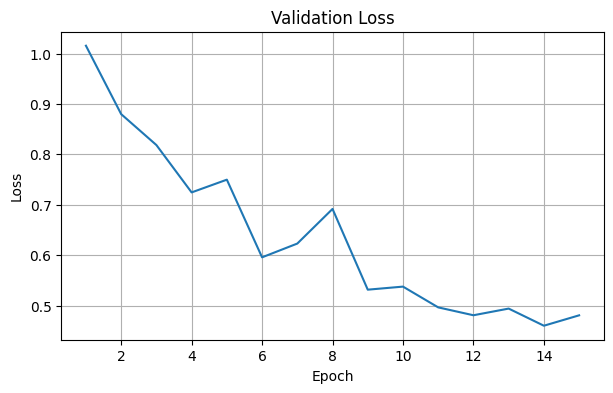

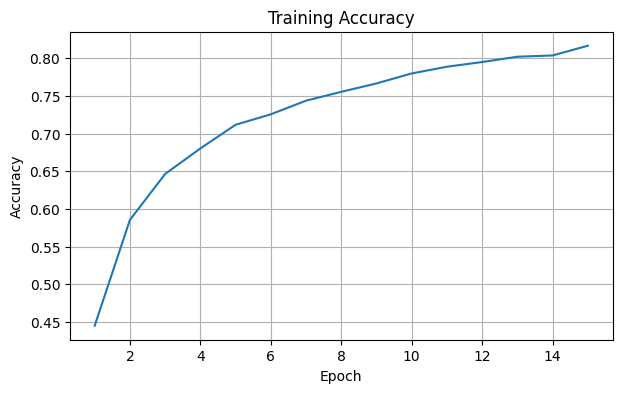

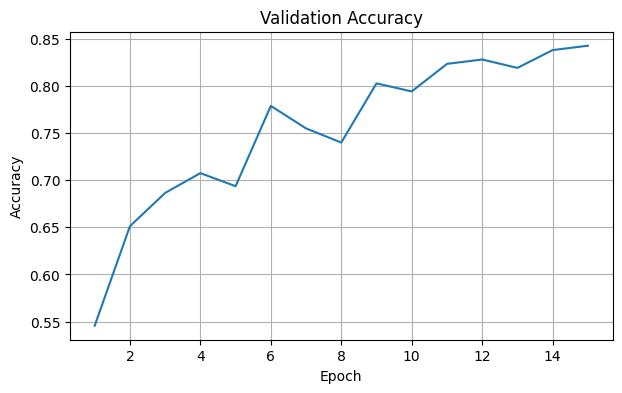

In [13]:

import matplotlib.pyplot as plt

epochs = range(1, len(history.history["loss"]) + 1)

# 1. Training Loss
plt.figure(figsize=(7, 4))
plt.plot(epochs, history.history["loss"])
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# 2. Validation Loss
plt.figure(figsize=(7, 4))
plt.plot(epochs, history.history["val_loss"])
plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# 3. Training Accuracy
plt.figure(figsize=(7, 4))
plt.plot(epochs, history.history["accuracy"])
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

# 4. Validation Accuracy
plt.figure(figsize=(7, 4))
plt.plot(epochs, history.history["val_accuracy"])
plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

#baseline CNN achieved 84.25% validation accuracy with a learning rate of 0.001.

In [14]:
# learning rate in a newly created cnn model

# Build a fresh CNN with a lower learning rate
def build_model(learning_rate=0.0005):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(150, 150, 3)),
        tf.keras.layers.Rescaling(1./255),

        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(64, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(128, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(6, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

lr_model = build_model(learning_rate=0.0005)

lr_history = lr_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 17s 40ms/step - accuracy: 0.4233 - loss: 1.3463 - val_accuracy: 0.5242 - val_loss: 1.1314
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.5493 - loss: 1.0751 - val_accuracy: 0.6094 - val_loss: 0.9437
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.6036 - loss: 0.9648 - val_accuracy: 0.6632 - val_loss: 0.8579
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.6432 - loss: 0.8876 - val_accuracy: 0.6907 - val_loss: 0.7876
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.6716 - loss: 0.8334 - val_accuracy: 0.6778 - val_loss: 0.8090
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.6864 - loss: 0.8029 - val_accuracy: 0.7056 - val_loss: 0.7512
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7066 - loss: 0.7621 - val_accuracy: 0.7206 - val_loss: 0.7261
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.7210 - loss: 0.7325 - 

In [15]:
#test learning rate = 0.002

lr_model_002 = build_model(learning_rate=0.002)

history_002 = lr_model_002.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 18s 41ms/step - accuracy: 0.4635 - loss: 1.2177 - val_accuracy: 0.5763 - val_loss: 0.9792
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.5749 - loss: 0.9853 - val_accuracy: 0.6066 - val_loss: 0.9165
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.6419 - loss: 0.8702 - val_accuracy: 0.6540 - val_loss: 0.8452
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.6843 - loss: 0.7915 - val_accuracy: 0.7541 - val_loss: 0.6562
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7317 - loss: 0.7032 - val_accuracy: 0.7263 - val_loss: 0.6983
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.7496 - loss: 0.6604 - val_accuracy: 0.7776 - val_loss: 0.5895
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.7592 - loss: 0.6381 - val_accuracy: 0.7912 - val_loss: 0.5645
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7772 - loss: 0.5892 - 

In [16]:
#building model with new tuned dropout rate with lr = 0.001
dropout_model = build_model(learning_rate=0.001)

dropout_history = dropout_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - accuracy: 0.4357 - loss: 1.2904 - val_accuracy: 0.5492 - val_loss: 1.0277
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.5598 - loss: 1.0286 - val_accuracy: 0.5645 - val_loss: 1.0293
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.6071 - loss: 0.9431 - val_accuracy: 0.6433 - val_loss: 0.8671
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.6638 - loss: 0.8381 - val_accuracy: 0.7021 - val_loss: 0.7666
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.6910 - loss: 0.7741 - val_accuracy: 0.7448 - val_loss: 0.6760
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7138 - loss: 0.7258 - val_accuracy: 0.7623 - val_loss: 0.6441
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.7370 - loss: 0.6899 - val_accuracy: 0.7669 - val_loss: 0.6209
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.7497 - loss: 0.6657 - 

In [17]:
#dropout changed from 0.5 to 0.2 testing

dropout02_model = build_model(learning_rate=0.001)

dropout02_history = dropout02_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - accuracy: 0.4337 - loss: 1.2846 - val_accuracy: 0.4227 - val_loss: 1.2214
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.5507 - loss: 1.0392 - val_accuracy: 0.5959 - val_loss: 0.9595
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.6185 - loss: 0.9261 - val_accuracy: 0.6540 - val_loss: 0.8753
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.6589 - loss: 0.8505 - val_accuracy: 0.7128 - val_loss: 0.7773
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 21s 30ms/step - accuracy: 0.6844 - loss: 0.7943 - val_accuracy: 0.6971 - val_loss: 0.7565
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.7022 - loss: 0.7514 - val_accuracy: 0.7555 - val_loss: 0.6413
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7248 - loss: 0.7091 - val_accuracy: 0.7655 - val_loss: 0.6326
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.7367 - loss: 0.6831 - 

In [18]:

experiments = {
    "Baseline (dropout 0.3, LR 0.001)": history,
    "Dropout 0.5": dropout_history,
    "Dropout 0.2": dropout02_history,
    "Learning rate 0.0005": lr_history,
    "Learning rate 0.002": history_002
}

for name, h in experiments.items():
    best_acc = max(h.history["val_accuracy"])
    best_loss = min(h.history["val_loss"])

    print(f"\n{name}")
    print(f"Best validation accuracy: {best_acc:.4f}")
    print(f"Lowest validation loss: {best_loss:.4f}")


Baseline (dropout 0.3, LR 0.001)
Best validation accuracy: 0.8425
Lowest validation loss: 0.4601

Dropout 0.5
Best validation accuracy: 0.8318
Lowest validation loss: 0.4841

Dropout 0.2
Best validation accuracy: 0.8307
Lowest validation loss: 0.4770

Learning rate 0.0005
Best validation accuracy: 0.7944
Lowest validation loss: 0.5531

Learning rate 0.002
Best validation accuracy: 0.8200
Lowest validation loss: 0.4970


In [19]:
#tuning number of filters
#filters changed from 32,64,128 with smaller cnn - 16,32,64
#lr = 0.001, dropout = 0.3
def build_small_model(learning_rate=0.001):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(150, 150, 3)),
        tf.keras.layers.Rescaling(1./255),

        tf.keras.layers.Conv2D(16, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(64, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(6, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


small_model = build_small_model()
small_model.summary()

small_history = small_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
            verbose=1
        )
    ],
    verbose=1
)

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_5 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 148, 148, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 74, 74, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 72, 72, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 34, 34, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,134 (109.90 KB)

 Trainable params: 28,134 (109.90 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 20s 38ms/step - accuracy: 0.4206 - loss: 1.3475 - val_accuracy: 0.5232 - val_loss: 1.1646
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.5288 - loss: 1.1118 - val_accuracy: 0.5756 - val_loss: 0.9994
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.5725 - loss: 1.0160 - val_accuracy: 0.6183 - val_loss: 0.9493
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.5956 - loss: 0.9669 - val_accuracy: 0.6454 - val_loss: 0.8773
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.6203 - loss: 0.9136 - val_accuracy: 0.6746 - val_loss: 0.8291
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.6375 - loss: 0.8792 - val_accuracy: 0.6924 - val_loss: 0.7888
Epoch 7/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.6608 - loss: 0.8341 - val_accuracy: 0.7170 - val_loss: 0.7257
Epoch 8/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.6924 - loss: 0.7861 - val_a

In [20]:
small_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_5 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 148, 148, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 74, 74, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 72, 72, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 34, 34, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,404 (329.71 KB)

 Trainable params: 28,134 (109.90 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 56,270 (219.81 KB)

In [21]:
import time

# Check whether the history contains the expected metrics
print(small_history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


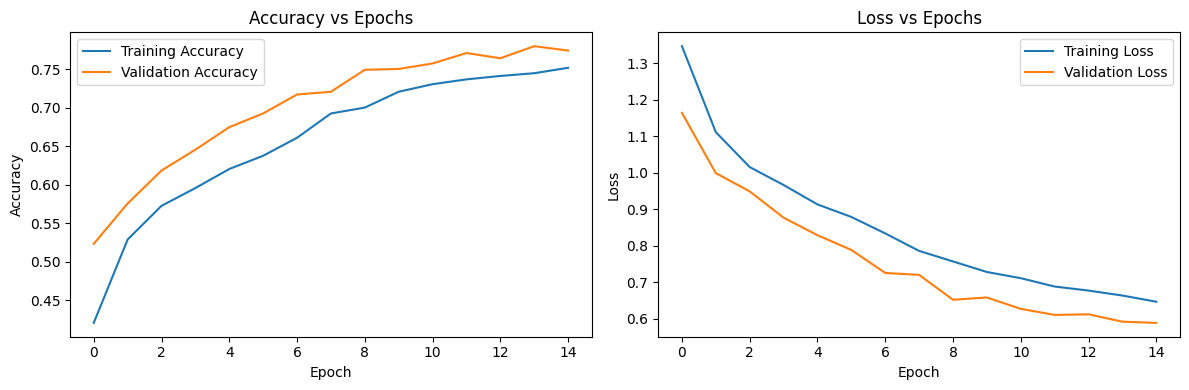

In [22]:
#plotting for smaller cnn
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(small_history.history['accuracy'], label='Training Accuracy')
plt.plot(small_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy vs Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(small_history.history['loss'], label='Training Loss')
plt.plot(small_history.history['val_loss'], label='Validation Loss')
plt.title('Loss vs Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [24]:
import os

root = "/content/intel_dataset"

print("Dataset folder exists:", os.path.exists(root))

if os.path.exists(root):
    for item in os.listdir(root):
        full_path = os.path.join(root, item)
        print("Folder:" if os.path.isdir(full_path) else "File:", item)

Dataset folder exists: True
Folder: seg_train
Folder: seg_pred
Folder: seg_test


In [27]:
import tensorflow as tf

test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/intel_dataset/seg_test/seg_test",
    image_size=(150, 150),
    batch_size=32,
    shuffle=False
)

print("Classes:", test_ds.class_names)

Found 3000 files belonging to 6 classes.
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [26]:
import os

root = "/content/intel_dataset/seg_test"

for item in os.listdir(root):
    full_path = os.path.join(root, item)
    print(item, "| Directory:", os.path.isdir(full_path))

    if os.path.isdir(full_path):
        print("  Contents:", os.listdir(full_path)[:5])

seg_test | Directory: True
  Contents: ['glacier', 'mountain', 'forest', 'buildings', 'street']


In [28]:
#evaluating baseline CNN on 3000 test images

test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8220 - loss: 0.4811
Test Accuracy: 82.20%
Test Loss: 0.4811


94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step


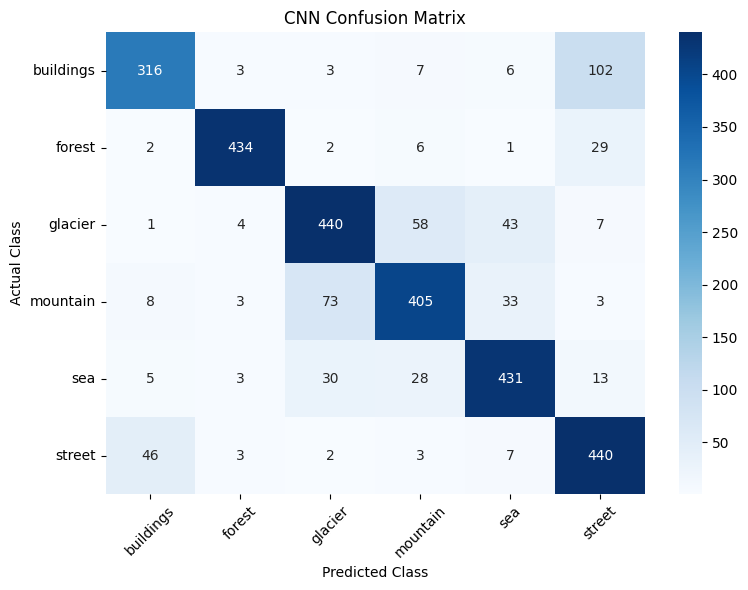

              precision    recall  f1-score   support

   buildings     0.8360    0.7231    0.7755       437
      forest     0.9644    0.9156    0.9394       474
     glacier     0.8000    0.7957    0.7978       553
    mountain     0.7988    0.7714    0.7849       525
         sea     0.8273    0.8451    0.8361       510
      street     0.7407    0.8782    0.8037       501

    accuracy                         0.8220      3000
   macro avg     0.8279    0.8215    0.8229      3000
weighted avg     0.8258    0.8220    0.8221      3000



In [29]:
#Confusion matrix and Classification Report

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# Actual labels
y_true = np.concatenate([y.numpy() for x, y in test_ds])

# Predicted labels
y_pred = np.argmax(model.predict(test_ds), axis=1)

# Class names
class_names = test_ds.class_names

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CNN Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))